> 👥 **Team project** completed by a U of T student team, including Ketan Khanna

> Foundations of Data Science (SCS 3250), Final Project · University of Toronto School of Continuing Studies · Winter 2020

# Introduction

  The primary focus of an NBA team’s executive management is to determine a player’s future value and whether they can contribute towards winning games. Predictive modelling and statistical analysis are of paramount importance for teams trying to draft or sign a free agent player that will provide a positive return on investment based on their eventual production. Determining a player’s future value in the NBA can only be accomplished by harnessing previously collected data of a player’s performance in the league. The focus of our project is to utilize predictive modelling (through a train and test set) to determine the peak Player Efficiency Rating (PER) of an NBA rookie based on the first 3 years of their performance in the NBA.

  We believe that PER is good measure of a player’s performance as its formula contains key variables indicative of a player’s level of play. Metrics such as points, assists, blocks, rebounds (offensive and defensive), steals and 3 pointers are used in conjunction with other efficiency metrics (Free Throw Percentage (FT%), Field Goal Percentage (FG%), etc.) to calculate the PER formula. By combining these variables with one another, PER becomes particularly important when analyzing a player’s overall basketball performance. As die-hard sports fans, we are extremely passionate about this project as we believe the foundations of data science will continue to be instrumental in developing tools and algorithms used by NBA teams when deciding whether to sign players to a specific valued ($) contract.


# Objectives

  Our main objective for this project is to harness PER data for basketball rookies during their first 3 years in the NBA to develop a predictive model capable of predicting their peak career PER. We hope to gain multiple insights from this project, which include how accurately our predictive model was able to determine a player’s peak PER and whether the metric itself is useful in determining a player’s value in the NBA. By all accounts, prior experience would suggest that a player who initially has a high PER upon entering the league continues to increase his rating as time goes on. Players such as Michael Jordan, Lebron James and Shaquille O’Neal are all examples of rookies that achieved a high PER during their first year and continued to dominate in the game of basketball thereafter. Nonetheless, it is through the development of our predictive model that we will be able to determine if this is always the case. Additionally, our model will be useful in determining as to what extent executive management can utilize data and predictive modeling to determine an NBA player's future productivity and success. An analysis will also be conducted to determine whether the model has any shortcomings in terms of predicting a player's value through PER. 

# Data Source

We found our data on Kaggle.com. The dataset contained information on every player within the NBA from 1950 to 2017. 
Dataset: https://www.kaggle.com/drgilermo/nba-players-stats

The data was broken down by season and featured three csv files:

*   Season_Stats.csv: contained player in-game statistics, this file was the most crucial for our analysis
*   Players.csv: contained information on the players such as height, weight and city of birth. We chose to exclude this file.
*   player_data.csv: this file was very similar to Players.csv, but contained a useful feature: the year the player began their career. 

In order to get the most recent data (2018 and 2019 data), we then turned to Basketball-reference.com. This site is where the Kaggle data originated from, making it easy to incorporate. Basketball-reference allows users to run queries and export direct to csv. 
https://www.basketball-reference.com/

Basketball-reference also provides a glossary containing explanations for every statistic that we use as features in our dataset: https://www.basketball-reference.com/about/glossary.html

# Import Libraries


In [0]:
#Import necessary libraries for data wrangling, visuals and modelling
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline  
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split 
from sklearn import metrics
from sklearn import preprocessing
from scipy import stats

/usr/local/lib/python3.6/dist-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


# Read in the Data

We have four CSV files. The first two are from Kaggle and the next two were scrapped from basketball-reference.com. These files are structured and very clean.

In [0]:
df1950to2017=pd.read_csv('data/Seasons_Stats.csv')
player_data=pd.read_csv('data/player_data.csv')
df2018=pd.read_csv('data/2018.csv')
df2019=pd.read_csv('data/2019.csv')


# Data Preperation

Below are the steps we took to prepare the data for modelling:

*   Identify and remove columns made up of entirely missing data. These rows were empty placeholders that served to physically seperate sections of data on basketball-reference.com (for visual purposes).
*   Combine the 1950-2017 data with the 2018 and 2019 data. This was easy since they have matching features.
*   Select only the features that we, as basketball fans, felt would be relevent to the model. Since the model predicts the PER metric, we considered what featured factored into the PER calculation. 
*   Remove rows of data where player name was missing. Since there were only 67 missing values, it made more sense to remove these, rather than invest time trying to impute them. Having a value for player name is essential, since we will group the data by name later on
*   Convert year from float to integer to get rid of the decimal
*   Addressed missing values for shooting statistics (3 point, 2 point, field goal and free throw percentages). These percentages are calculated by dividing shots made by shots attempted. However, some players did not attempt any shots and therefore had a missing value. We addressed this by imputing a '0'.
*   Merged the 1950-2019 dataset with the set containing player information (including draft year)
*   Since we want our training set to only include players during their first three seasons in the NBA, we engineered a new variable called 'Season', calculated by subtracting the year a player was drafted from the current year
*   Filtered out players who played less than 10 games in a season. Since there are 82 games per season we wanted to reduce outliers caused by insufficent sample sizes.













In [0]:
#Combine 2018 and 2019 data, as these sets have matching columns
df20182019=pd.concat([df2018, df2019])

In [0]:
df1950to2017.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24691 entries, 0 to 24690
Data columns (total 53 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  24691 non-null  int64  
 1   Year        24624 non-null  float64
 2   Player      24624 non-null  object 
 3   Pos         24624 non-null  object 
 4   Age         24616 non-null  float64
 5   Tm          24624 non-null  object 
 6   G           24624 non-null  float64
 7   GS          18233 non-null  float64
 8   MP          24138 non-null  float64
 9   PER         24101 non-null  float64
 10  TS%         24538 non-null  float64
 11  3PAr        18839 non-null  float64
 12  FTr         24525 non-null  float64
 13  ORB%        20792 non-null  float64
 14  DRB%        20792 non-null  float64
 15  TRB%        21571 non-null  float64
 16  AST%        22555 non-null  float64
 17  STL%        20792 non-null  float64
 18  BLK%        20792 non-null  float64
 19  TOV%        19582 non-nul

In [0]:
df20182019.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1372 entries, 0 to 707
Data columns (total 53 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Year         1372 non-null   int64  
 1   Player       1372 non-null   object 
 2   Pos          1372 non-null   object 
 3   Age          1372 non-null   int64  
 4   Tm           1372 non-null   object 
 5   G            1372 non-null   int64  
 6   GS           1372 non-null   int64  
 7   MP           1372 non-null   int64  
 8   PER          1372 non-null   float64
 9   TS%          1362 non-null   float64
 10  3PAr         1362 non-null   float64
 11  FTr          1362 non-null   float64
 12  ORB%         1372 non-null   float64
 13  DRB%         1372 non-null   float64
 14  TRB%         1372 non-null   float64
 15  AST%         1372 non-null   float64
 16  STL%         1372 non-null   float64
 17  BLK%         1372 non-null   float64
 18  TOV%         1362 non-null   float64
 19  USG%   

In [0]:
#Both dataframes have some columns full of null values. Remove those.
df1950to2017=df1950to2017.drop(columns=['blanl', 'blank2','Unnamed: 0'])
df20182019=df20182019.drop(columns=['Unnamed: 20', 'Unnamed: 25','MP.1'])

In [0]:
#Combine the two dataframes
dffinal=pd.concat([df1950to2017, df20182019])

In [0]:
dffinal.head()

,Year,Player,Pos,Age,Tm,G,GS,MP,PER,TS%,3PAr,FTr,ORB%,DRB%,TRB%,AST%,STL%,BLK%,TOV%,USG%,OWS,DWS,WS,WS/48,OBPM,DBPM,BPM,VORP,FG,FGA,FG%,3P,3PA,3P%,2P,2PA,2P%,eFG%,FT,FTA,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
0,1950.0,Curly Armstrong,G-F,31.0,FTW,63.0,NaN,NaN,NaN,0.368,NaN,0.467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.1,3.6,3.5,NaN,NaN,NaN,NaN,NaN,144.0,516.0,0.279,NaN,NaN,NaN,144.0,516.0,0.279,0.279,170.0,241.0,0.705,NaN,NaN,NaN,176.0,NaN,NaN,NaN,217.0,458.0
1,1950.0,Cliff Barker,SG,29.0,INO,49.0,NaN,NaN,NaN,0.435,NaN,0.387,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.6,0.6,2.2,NaN,NaN,NaN,NaN,NaN,102.0,274.0,0.372,NaN,NaN,NaN,102.0,274.0,0.372,0.372,75.0,106.0,0.708,NaN,NaN,NaN,109.0,NaN,NaN,NaN,99.0,279.0
2,1950.0,Leo Barnhorst,SF,25.0,CHS,67.0,NaN,NaN,NaN,0.394,NaN,0.259,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.9,2.8,3.6,NaN,NaN,NaN,NaN,NaN,174.0,499.0,0.349,NaN,NaN,NaN,174.0,499.0,0.349,0.349,90.0,129.0,0.698,NaN,NaN,NaN,140.0,NaN,NaN,NaN,192.0,438.0
3,1950.0,Ed Bartels,F,24.0,TOT,15.0,NaN,NaN,NaN,0.312,NaN,0.395,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.5,-0.1,-0.6,NaN,NaN,NaN,NaN,NaN,22.0,86.0,0.256,NaN,NaN,NaN,22.0,86.0,0.256,0.256,19.0,34.0,0.559,NaN,NaN,NaN,20.0,NaN,NaN,NaN,29.0,63.0
4,1950.0,Ed Bartels,F,24.0,DNN,13.0,NaN,NaN,NaN,0.308,NaN,0.378,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.5,-0.1,-0.6,NaN,NaN,NaN,NaN,NaN,21.0,82.0,0.256,NaN,NaN,NaN,21.0,82.0,0.256,0.256,17.0,31.0,0.548,NaN,NaN,NaN,20.0,NaN,NaN,NaN,27.0,59.0


In [0]:
# There is A LOT of information here. 
#To simplify, we are removing stats which will not be relevant to our analysis. We used domain knowledge of the sport of basketball to derive this removal list.
droplist=['VORP','WS/48','Pos','2P', '2PA', '3P', '3PA','PF', 'ORB', 'DRB','FT', 'FTA','FG', 'FGA', 'ORB%', 'DRB%', 'OWS', 'DWS', 'OBPM', 'DBPM', 'BPM']
dffinal=dffinal.drop(columns=droplist)

In [0]:
dffinal.head()

,Year,Player,Age,Tm,G,GS,MP,PER,TS%,3PAr,FTr,TRB%,AST%,STL%,BLK%,TOV%,USG%,WS,FG%,3P%,2P%,eFG%,FT%,TRB,AST,STL,BLK,TOV,PTS
0,1950.0,Curly Armstrong,31.0,FTW,63.0,NaN,NaN,NaN,0.368,NaN,0.467,NaN,NaN,NaN,NaN,NaN,NaN,3.5,0.279,NaN,0.279,0.279,0.705,NaN,176.0,NaN,NaN,NaN,458.0
1,1950.0,Cliff Barker,29.0,INO,49.0,NaN,NaN,NaN,0.435,NaN,0.387,NaN,NaN,NaN,NaN,NaN,NaN,2.2,0.372,NaN,0.372,0.372,0.708,NaN,109.0,NaN,NaN,NaN,279.0
2,1950.0,Leo Barnhorst,25.0,CHS,67.0,NaN,NaN,NaN,0.394,NaN,0.259,NaN,NaN,NaN,NaN,NaN,NaN,3.6,0.349,NaN,0.349,0.349,0.698,NaN,140.0,NaN,NaN,NaN,438.0
3,1950.0,Ed Bartels,24.0,TOT,15.0,NaN,NaN,NaN,0.312,NaN,0.395,NaN,NaN,NaN,NaN,NaN,NaN,-0.6,0.256,NaN,0.256,0.256,0.559,NaN,20.0,NaN,NaN,NaN,63.0
4,1950.0,Ed Bartels,24.0,DNN,13.0,NaN,NaN,NaN,0.308,NaN,0.378,NaN,NaN,NaN,NaN,NaN,NaN,-0.6,0.256,NaN,0.256,0.256,0.548,NaN,20.0,NaN,NaN,NaN,59.0


In [0]:
dffinal.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 26063 entries, 0 to 707
Data columns (total 29 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Year    25996 non-null  float64
 1   Player  25996 non-null  object 
 2   Age     25988 non-null  float64
 3   Tm      25996 non-null  object 
 4   G       25996 non-null  float64
 5   GS      19605 non-null  float64
 6   MP      25510 non-null  float64
 7   PER     25473 non-null  float64
 8   TS%     25900 non-null  float64
 9   3PAr    20201 non-null  float64
 10  FTr     25887 non-null  float64
 11  TRB%    22943 non-null  float64
 12  AST%    23927 non-null  float64
 13  STL%    22164 non-null  float64
 14  BLK%    22164 non-null  float64
 15  TOV%    20944 non-null  float64
 16  USG%    21012 non-null  float64
 17  WS      25957 non-null  float64
 18  FG%     25887 non-null  float64
 19  3P%     16676 non-null  float64
 20  2P%     25835 non-null  float64
 21  eFG%    25887 non-null  float64
 22  

In [0]:
#Post merger, we have 67 rows that are missing data for Player. Player is essential for our analysis so we are removing these
dffinal=dffinal.dropna(subset=['Player'])

In [0]:
dffinal.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 25996 entries, 0 to 707
Data columns (total 29 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Year    25996 non-null  float64
 1   Player  25996 non-null  object 
 2   Age     25988 non-null  float64
 3   Tm      25996 non-null  object 
 4   G       25996 non-null  float64
 5   GS      19605 non-null  float64
 6   MP      25510 non-null  float64
 7   PER     25473 non-null  float64
 8   TS%     25900 non-null  float64
 9   3PAr    20201 non-null  float64
 10  FTr     25887 non-null  float64
 11  TRB%    22943 non-null  float64
 12  AST%    23927 non-null  float64
 13  STL%    22164 non-null  float64
 14  BLK%    22164 non-null  float64
 15  TOV%    20944 non-null  float64
 16  USG%    21012 non-null  float64
 17  WS      25957 non-null  float64
 18  FG%     25887 non-null  float64
 19  3P%     16676 non-null  float64
 20  2P%     25835 non-null  float64
 21  eFG%    25887 non-null  float64
 22  

In [0]:
#Convert year from float to integer
dffinal.Year=dffinal.Year.astype(int)

In [0]:
# 3P% has a lot of missing values. Investigation reveals that this is because these players took 0 3 point shots. 
dffinal[dffinal['3P%'].isna()]

,Year,Player,Age,Tm,G,GS,MP,PER,TS%,3PAr,FTr,TRB%,AST%,STL%,BLK%,TOV%,USG%,WS,FG%,3P%,2P%,eFG%,FT%,TRB,AST,STL,BLK,TOV,PTS
0,1950,Curly Armstrong,31.0,FTW,63.0,NaN,NaN,NaN,0.368,NaN,0.467,NaN,NaN,NaN,NaN,NaN,NaN,3.5,0.279,NaN,0.279,0.279,0.705,NaN,176.0,NaN,NaN,NaN,458.0
1,1950,Cliff Barker,29.0,INO,49.0,NaN,NaN,NaN,0.435,NaN,0.387,NaN,NaN,NaN,NaN,NaN,NaN,2.2,0.372,NaN,0.372,0.372,0.708,NaN,109.0,NaN,NaN,NaN,279.0
2,1950,Leo Barnhorst,25.0,CHS,67.0,NaN,NaN,NaN,0.394,NaN,0.259,NaN,NaN,NaN,NaN,NaN,NaN,3.6,0.349,NaN,0.349,0.349,0.698,NaN,140.0,NaN,NaN,NaN,438.0
3,1950,Ed Bartels,24.0,TOT,15.0,NaN,NaN,NaN,0.312,NaN,0.395,NaN,NaN,NaN,NaN,NaN,NaN,-0.6,0.256,NaN,0.256,0.256,0.559,NaN,20.0,NaN,NaN,NaN,63.0
4,1950,Ed Bartels,24.0,DNN,13.0,NaN,NaN,NaN,0.308,NaN,0.378,NaN,NaN,NaN,NaN,NaN,NaN,-0.6,0.256,NaN,0.256,0.256,0.548,NaN,20.0,NaN,NaN,NaN,59.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
703,2019,Tyler Zeller\zellety01,29.0,MEM,4.0,1.0,82.0,19.4,0.640,0.0,0.643,12.3,6.2,0.6,3.5,10.0,21.8,0.3,0.571,NaN,0.571,0.571,0.778,18.0,3.0,1.0,3.0,4.0,46.0
704,2019,Ante Žižić\zizican01,22.0,CLE,59.0,25.0,1082.0,16.2,0.590,0.0,0.399,16.4,7.7,0.6,1.8,13.6,18.2,2.0,0.553,NaN,0.553,0.553,0.705,320.0,53.0,13.0,22.0,61.0,459.0
705,2019,Ivica Zubac\zubaciv01,21.0,TOT,59.0,37.0,1040.0,18.9,0.604,0.0,0.332,18.2,9.1,0.6,4.0,13.9,20.3,3.2,0.559,NaN,0.559,0.559,0.802,362.0,63.0,14.0,51.0,70.0,525.0
706,2019,Ivica Zubac\zubaciv01,21.0,LAL,33.0,12.0,516.0,19.5,0.633,0.0,0.342,16.2,7.3,0.4,4.3,12.9,20.5,1.8,0.580,NaN,0.580,0.580,0.864,162.0,25.0,4.0,27.0,33.0,281.0


In [0]:
#Fill in these missing values with a 0
dffinal['3P%']=dffinal['3P%'].fillna(0)

In [0]:
#The same holds true for other shot statistics
#Fill in these missing values with a 0
dffinal['FT%']=dffinal['FT%'].fillna(0)
#Fill in these missing values with a 0
dffinal['2P%']=dffinal['2P%'].fillna(0)
#Fill in these missing values with a 0
dffinal['FG%']=dffinal['FG%'].fillna(0)

In [0]:
#Player data contains a column that shows what year a player was drafted. Extract this
player_data=player_data.iloc[:, :2]

In [0]:
#Merge this year column onto our dataframe
dffinal=dffinal.merge(player_data, left_on='Player', right_on='name')

In [0]:
#Derive a column to indicate what season a player is on. 1 would be a rookie year.
dffinal['Season']=(dffinal.Year-dffinal['year_start'])+1

In [0]:
dffinal.head()

,Year,Player,Age,Tm,G,GS,MP,PER,TS%,3PAr,FTr,TRB%,AST%,STL%,BLK%,TOV%,USG%,WS,FG%,3P%,2P%,eFG%,FT%,TRB,AST,STL,BLK,TOV,PTS,name,year_start,Season
0,1950,Curly Armstrong,31.0,FTW,63.0,NaN,NaN,NaN,0.368,NaN,0.467,NaN,NaN,NaN,NaN,NaN,NaN,3.5,0.279,0.0,0.279,0.279,0.705,NaN,176.0,NaN,NaN,NaN,458.0,Curly Armstrong,1949,2
1,1951,Curly Armstrong,32.0,FTW,38.0,NaN,NaN,NaN,0.372,NaN,0.388,NaN,NaN,NaN,NaN,NaN,NaN,0.6,0.310,0.0,0.310,0.310,0.644,89.0,77.0,NaN,NaN,NaN,202.0,Curly Armstrong,1949,3
2,1950,Cliff Barker,29.0,INO,49.0,NaN,NaN,NaN,0.435,NaN,0.387,NaN,NaN,NaN,NaN,NaN,NaN,2.2,0.372,0.0,0.372,0.372,0.708,NaN,109.0,NaN,NaN,NaN,279.0,Cliff Barker,1950,1
3,1951,Cliff Barker,30.0,INO,56.0,NaN,NaN,NaN,0.322,NaN,0.381,NaN,NaN,NaN,NaN,NaN,NaN,-0.2,0.252,0.0,0.252,0.252,0.649,100.0,115.0,NaN,NaN,NaN,152.0,Cliff Barker,1950,2
4,1952,Cliff Barker,31.0,INO,44.0,NaN,494.0,10.8,0.343,NaN,0.317,NaN,NaN,NaN,NaN,NaN,NaN,0.1,0.298,0.0,0.298,0.298,0.588,81.0,70.0,NaN,NaN,NaN,126.0,Cliff Barker,1950,3


In [0]:
#Filter out players who played less than 9 games in a season. We did this because small game sample sizes led to poor model performance 
dffinal=dffinal[dffinal.G>9]

# Build a training set


Below are the steps taken in creating the training model:
*   We wanted to train the model on data from the years 1984 to 2006, so we filtered the data accordingly.
*   Since we wanted to train the model based on the first three years of a player's career, we filtered the set based on our engineered 'Season' feature to only include values of 1-3.
*   The model is trying to predict the maximum PER a player will achieve during their career. So we derived this value for each player within the training set. 
*   Take the average for each feature for each player for their first three years
*   Remove missing row values
*   Remove features that we will not use within our model







In [0]:
#Filter our data to only include the years 1984 to 2006 and the first three years of a player's career
dftrain=dffinal[(dffinal.Year>=1984) & (dffinal.Year<=2006)]
dftrain=dftrain[(dftrain.Season<=3) & (dftrain.Season>=0)]

In [0]:
#Find Max PER per player
MAXPER=dffinal.groupby(by="Player").max()['PER']
MAXPER

Player
A.C. Green            17.8
A.J. English          12.5
A.J. Guyton           11.8
A.J. Hammons           8.4
A.J. Price            17.1
                      ... 
Zeljko Rebraca        16.2
Zendon Hamilton       18.2
Zoran Dragic           8.2
Zoran Planinic        12.5
Zydrunas Ilgauskas    21.9
Name: PER, Length: 3335, dtype: float64

In [0]:
#Merge maxper onto the training set. MAXPER is our Y
dftrain2=dftrain.merge(MAXPER, left_on='Player', right_on='Player')
dftrain2.head(5)

,Year,Player,Age,Tm,G,GS,MP,PER_x,TS%,3PAr,FTr,TRB%,AST%,STL%,BLK%,TOV%,USG%,WS,FG%,3P%,2P%,eFG%,FT%,TRB,AST,STL,BLK,TOV,PTS,name,year_start,Season,PER_y
0,2005,Luke Jackson,23.0,CLE,10.0,0.0,43.0,16.3,0.489,0.222,0.222,8.2,13.4,0.0,0.0,6.3,33.3,0.1,0.370,0.667,0.286,0.444,0.833,6.0,3.0,0.0,0.0,2.0,29.0,Luke Jackson,2005,1,16.3
1,2006,Luke Jackson,24.0,CLE,36.0,0.0,315.0,7.9,0.482,0.424,0.388,7.5,12.4,1.9,0.5,23.8,19.2,0.0,0.341,0.333,0.347,0.412,0.788,40.0,25.0,11.0,2.0,31.0,96.0,Luke Jackson,2005,2,16.3
2,1984,Sam Williams,24.0,TOT,77.0,12.0,1434.0,13.2,0.508,0.002,0.325,13.4,6.1,2.3,4.3,16.7,17.0,2.7,0.473,0.000,0.474,0.473,0.657,339.0,62.0,68.0,106.0,99.0,500.0,Sam Williams,1982,3,15.6
3,1984,Sam Williams,24.0,PHI,70.0,12.0,1375.0,13.0,0.509,0.002,0.328,13.5,6.2,2.2,4.3,17.2,16.8,2.6,0.477,0.000,0.478,0.477,0.647,326.0,60.0,62.0,103.0,96.0,472.0,Sam Williams,1982,3,15.6
4,2003,Mike Dunleavy,22.0,GSW,82.0,3.0,1305.0,12.5,0.505,0.360,0.240,8.7,12.6,2.1,1.0,15.7,17.8,1.5,0.403,0.347,0.434,0.465,0.780,214.0,106.0,53.0,19.0,86.0,466.0,Mike Dunleavy,2003,1,17.3


In [0]:
#Take the average of the three years the player spent in the league
dftrain3=dftrain2.groupby(by="Player").mean()

In [0]:
dftrain3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1412 entries, A.C. Green to Zydrunas Ilgauskas
Data columns (total 30 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Year        1412 non-null   float64
 1   Age         1412 non-null   float64
 2   G           1412 non-null   float64
 3   GS          1412 non-null   float64
 4   MP          1412 non-null   float64
 5   PER_x       1412 non-null   float64
 6   TS%         1412 non-null   float64
 7   3PAr        1412 non-null   float64
 8   FTr         1412 non-null   float64
 9   TRB%        1412 non-null   float64
 10  AST%        1412 non-null   float64
 11  STL%        1412 non-null   float64
 12  BLK%        1412 non-null   float64
 13  TOV%        1412 non-null   float64
 14  USG%        1412 non-null   float64
 15  WS          1412 non-null   float64
 16  FG%         1412 non-null   float64
 17  3P%         1412 non-null   float64
 18  2P%         1412 non-null   float64
 19  eFG%     

In [0]:
#There are some mising values in certain rows. It's not a big number, so drop those
dftrain3=dftrain3.dropna(axis=0)


In [0]:
dftrain3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1412 entries, A.C. Green to Zydrunas Ilgauskas
Data columns (total 30 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Year        1412 non-null   float64
 1   Age         1412 non-null   float64
 2   G           1412 non-null   float64
 3   GS          1412 non-null   float64
 4   MP          1412 non-null   float64
 5   PER_x       1412 non-null   float64
 6   TS%         1412 non-null   float64
 7   3PAr        1412 non-null   float64
 8   FTr         1412 non-null   float64
 9   TRB%        1412 non-null   float64
 10  AST%        1412 non-null   float64
 11  STL%        1412 non-null   float64
 12  BLK%        1412 non-null   float64
 13  TOV%        1412 non-null   float64
 14  USG%        1412 non-null   float64
 15  WS          1412 non-null   float64
 16  FG%         1412 non-null   float64
 17  3P%         1412 non-null   float64
 18  2P%         1412 non-null   float64
 19  eFG%     

In [0]:
#Drop columns we wont need inside our model
droplist3=["Year", "Season", "year_start", "Age"]
dftrain3=dftrain3.drop(columns=droplist3)
dftrain3.head(5)

,G,GS,MP,PER_x,TS%,3PAr,FTr,TRB%,AST%,STL%,BLK%,TOV%,USG%,WS,FG%,3P%,2P%,eFG%,FT%,TRB,AST,STL,BLK,TOV,PTS,PER_y
Player,,,,,,,,,,,,,,,,,,,,,,,,,,
A.C. Green,81.0,45.666667,2139.333333,14.00,0.581333,0.0090,0.500667,14.866667,4.433333,1.533333,1.566667,14.366667,14.70,6.266667,0.526667,0.055667,0.5310,0.5270,0.721333,568.666667,77.0,68.666667,58.0,107.0,770.0,17.8
A.J. English,75.5,9.000000,1554.000000,11.55,0.480000,0.0470,0.241000,5.550000,15.850000,0.900000,0.450000,11.950000,23.70,0.550000,0.436000,0.136500,0.4505,0.4385,0.774000,157.500000,160.0,28.500000,12.0,101.5,751.0,12.5
A.J. Guyton,39.0,7.000000,618.500000,11.05,0.486000,0.4315,0.102500,3.800000,20.850000,0.850000,0.750000,11.650000,19.35,0.200000,0.383500,0.382500,0.3810,0.4660,0.824000,40.000000,72.5,9.500000,6.0,30.5,221.0,11.8
Aaron McKie,58.4,23.000000,1267.200000,12.54,0.519000,0.2268,0.292600,8.260000,15.360000,2.420000,1.080000,16.060000,15.86,2.860000,0.425200,0.381800,0.4298,0.4692,0.791600,175.000000,123.2,56.400000,16.2,70.8,404.6,15.8
Aaron Miles,19.0,0.000000,118.000000,6.00,0.405000,0.0000,0.222000,6.600000,29.500000,1.700000,0.600000,35.800000,11.60,0.000000,0.333000,0.000000,0.3330,0.3330,1.000000,14.000000,24.0,4.000000,1.0,11.0,16.0,6.0


# Data Exploration

Player
Darrell Armstrong    32.4
LeBron James         31.7
Dwyane Wade          30.4
Tracy McGrady        30.3
Chris Paul           30.0
Kevin Garnett        29.4
Dirk Nowitzki        28.1
Kobe Bryant          28.0
Amar'e Stoudemire    27.6
Tim Duncan           27.1
Name: PER_y, dtype: float64

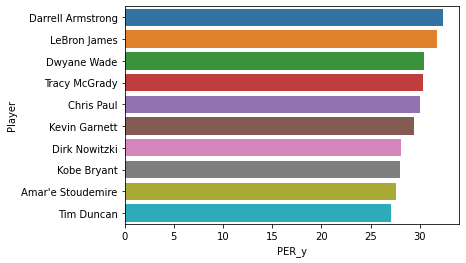

In [0]:
# Plot the players with the highest PER values to visualize the game's biggest stars 
dftrain3.sort_values('PER_y', ascending=False, inplace=True)

top_10_df = dftrain3.iloc[:10,]
top_10_plot = sns.barplot(y=top_10_df.index, x="PER_y", data=top_10_df)
display(top_10_df.iloc[:,-1])

Among all players in the dataset, Darrell Armstrong had the highest peak PER (32.4 in 1996), followed by LeBron James (31.7 in 2009) and Dwyane Wade (30.4 in 2009). 

While it is not surprising to see the names of so many outstanding players and future Hall of Famers in the top 10, it is surprising to see Darrell Armstrong at the top. Anecdotally, he is less known than any other player on the list. Investigating further, we can see this is because Armstrong was a relative 'one-shot wonder', registering PER above 23 in just a single season. Comparatively, LeBron James, who many consider to be the greatest player in the modern era, registered PER above 23 in 13 different seasons, including 4 seasons with PER above 30.

In [0]:
# Investigate the correlation between each feature and the target (PER_y). To do this we must first build a function to calculate R-squared.
def r2(x, y):
    return stats.pearsonr(x, y)[0] ** 2

,R2 with PER_y
PER_y,1.000000e+00
PER_x,7.190283e-01
WS,4.141383e-01
PTS,3.720136e-01
TS%,3.682500e-01
MP,3.381021e-01
eFG%,3.160963e-01
TOV,3.144813e-01
2P%,2.943544e-01
STL,2.897720e-01


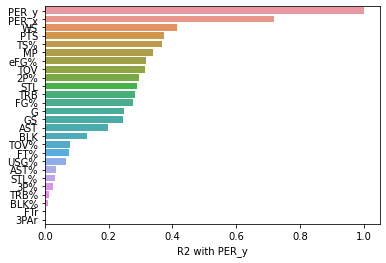

In [0]:
# Call this function to build a DataFrame containing correlations 
feature_temp_list, r2_temp_list = [],[]

for feature in list(dftrain3):
    feature_temp_list.append(feature)
    r2_temp_list.append(r2(dftrain3[feature], dftrain3['PER_y']))

corr_df = pd.DataFrame(r2_temp_list, columns=['R2 with PER_y'], index=feature_temp_list)
corr_df.sort_values('R2 with PER_y', ascending=False, inplace=True)
display(corr_df)

# Visualize this data in a barplot
corr_barplot = sns.barplot(y=corr_df.index, x="R2 with PER_y", data=corr_df, label="PER_y")


Unsurprisingly, of all features single-season PER (PER_x) was most correlated with career max PER (PER_y). Beyond this, the stats most correlated to PER_y were Win Share (WS), Points (PTS), True Shooting % (TS%), and Minutes Played (MP).

These high correlations are logical because all 4 statistics are intuitively associated with basketball talent. Win Share estimates the number of wins contributed by a player, and is a catch-all advanced statistic similar to PER. Points are a key input to the PER calculation that can be understood by even the most casual of fans. True Shooting % is a measure of shooting talent that takes into account field goals, 3-pt field goals, and free throws, while it's intuitive that better players would play more minutes.

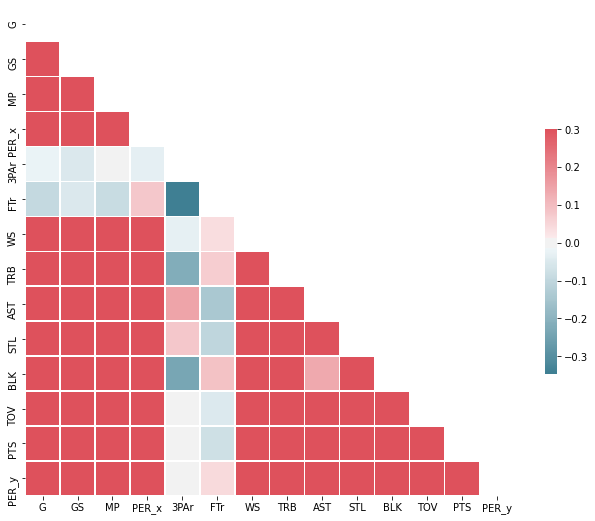

In [0]:
#Relationship between variebles using heatmap
corr = dfcharts.corr()
mask = np.triu(np.ones_like(corr, dtype=np.bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))
cmap = sns.diverging_palette(220, 10, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

The example heatmap above shows the relationship between variables with numerical value. Each cell reports a numeric count, like in a standard data table, but the count is accompanied by a color, with larger counts associated with red color and lower with blue, each one in different shades. From the heat map, we can see strong relationship between almost all the variables, except the FTr (Free Throw Attempts) and 3PAr (3-Point Field Goal Attempts) and this is becasue columns had missing values that we change to 0.

In [0]:
dfcharts.corr()

,G,GS,MP,PER_x,3PAr,FTr,WS,TRB,AST,STL,BLK,TOV,PTS,PER_y
G,1.000000,0.684580,0.862307,0.514649,-0.018410,-0.092669,0.698985,0.733075,0.596876,0.732064,0.486492,0.776600,0.770728,0.498998
GS,0.684580,1.000000,0.910793,0.532959,-0.048510,-0.050382,0.810684,0.802704,0.672772,0.771642,0.553252,0.861388,0.878125,0.493260
MP,0.862307,0.910793,1.000000,0.609661,0.012443,-0.084916,0.869850,0.843623,0.742220,0.862721,0.545766,0.930918,0.952355,0.581466
PER_x,0.514649,0.532959,0.609661,1.000000,-0.032351,0.079258,0.698968,0.577469,0.457046,0.560702,0.392069,0.586473,0.655688,0.847955
3PAr,-0.018410,-0.048510,0.012443,-0.032351,1.000000,-0.345643,-0.029999,-0.216193,0.148134,0.078965,-0.236381,-0.010778,-0.000059,0.000874
FTr,-0.092669,-0.050382,-0.084916,0.079258,-0.345643,1.000000,0.039687,0.069173,-0.141260,-0.101501,0.090487,-0.046812,-0.075515,0.043969
WS,0.698985,0.810684,0.869850,0.698968,-0.029999,0.039687,1.000000,0.808817,0.635390,0.758399,0.548109,0.787178,0.870167,0.643536
TRB,0.733075,0.802704,0.843623,0.577469,-0.216193,0.069173,0.808817,1.000000,0.401917,0.610359,0.741254,0.766603,0.797474,0.531585
AST,0.596876,0.672772,0.742220,0.457046,0.148134,-0.141260,0.635390,0.401917,1.000000,0.848132,0.134857,0.810083,0.701730,0.443959
STL,0.732064,0.771642,0.862721,0.560702,0.078965,-0.101501,0.758399,0.610359,0.848132,1.000000,0.323247,0.857747,0.818466,0.538305


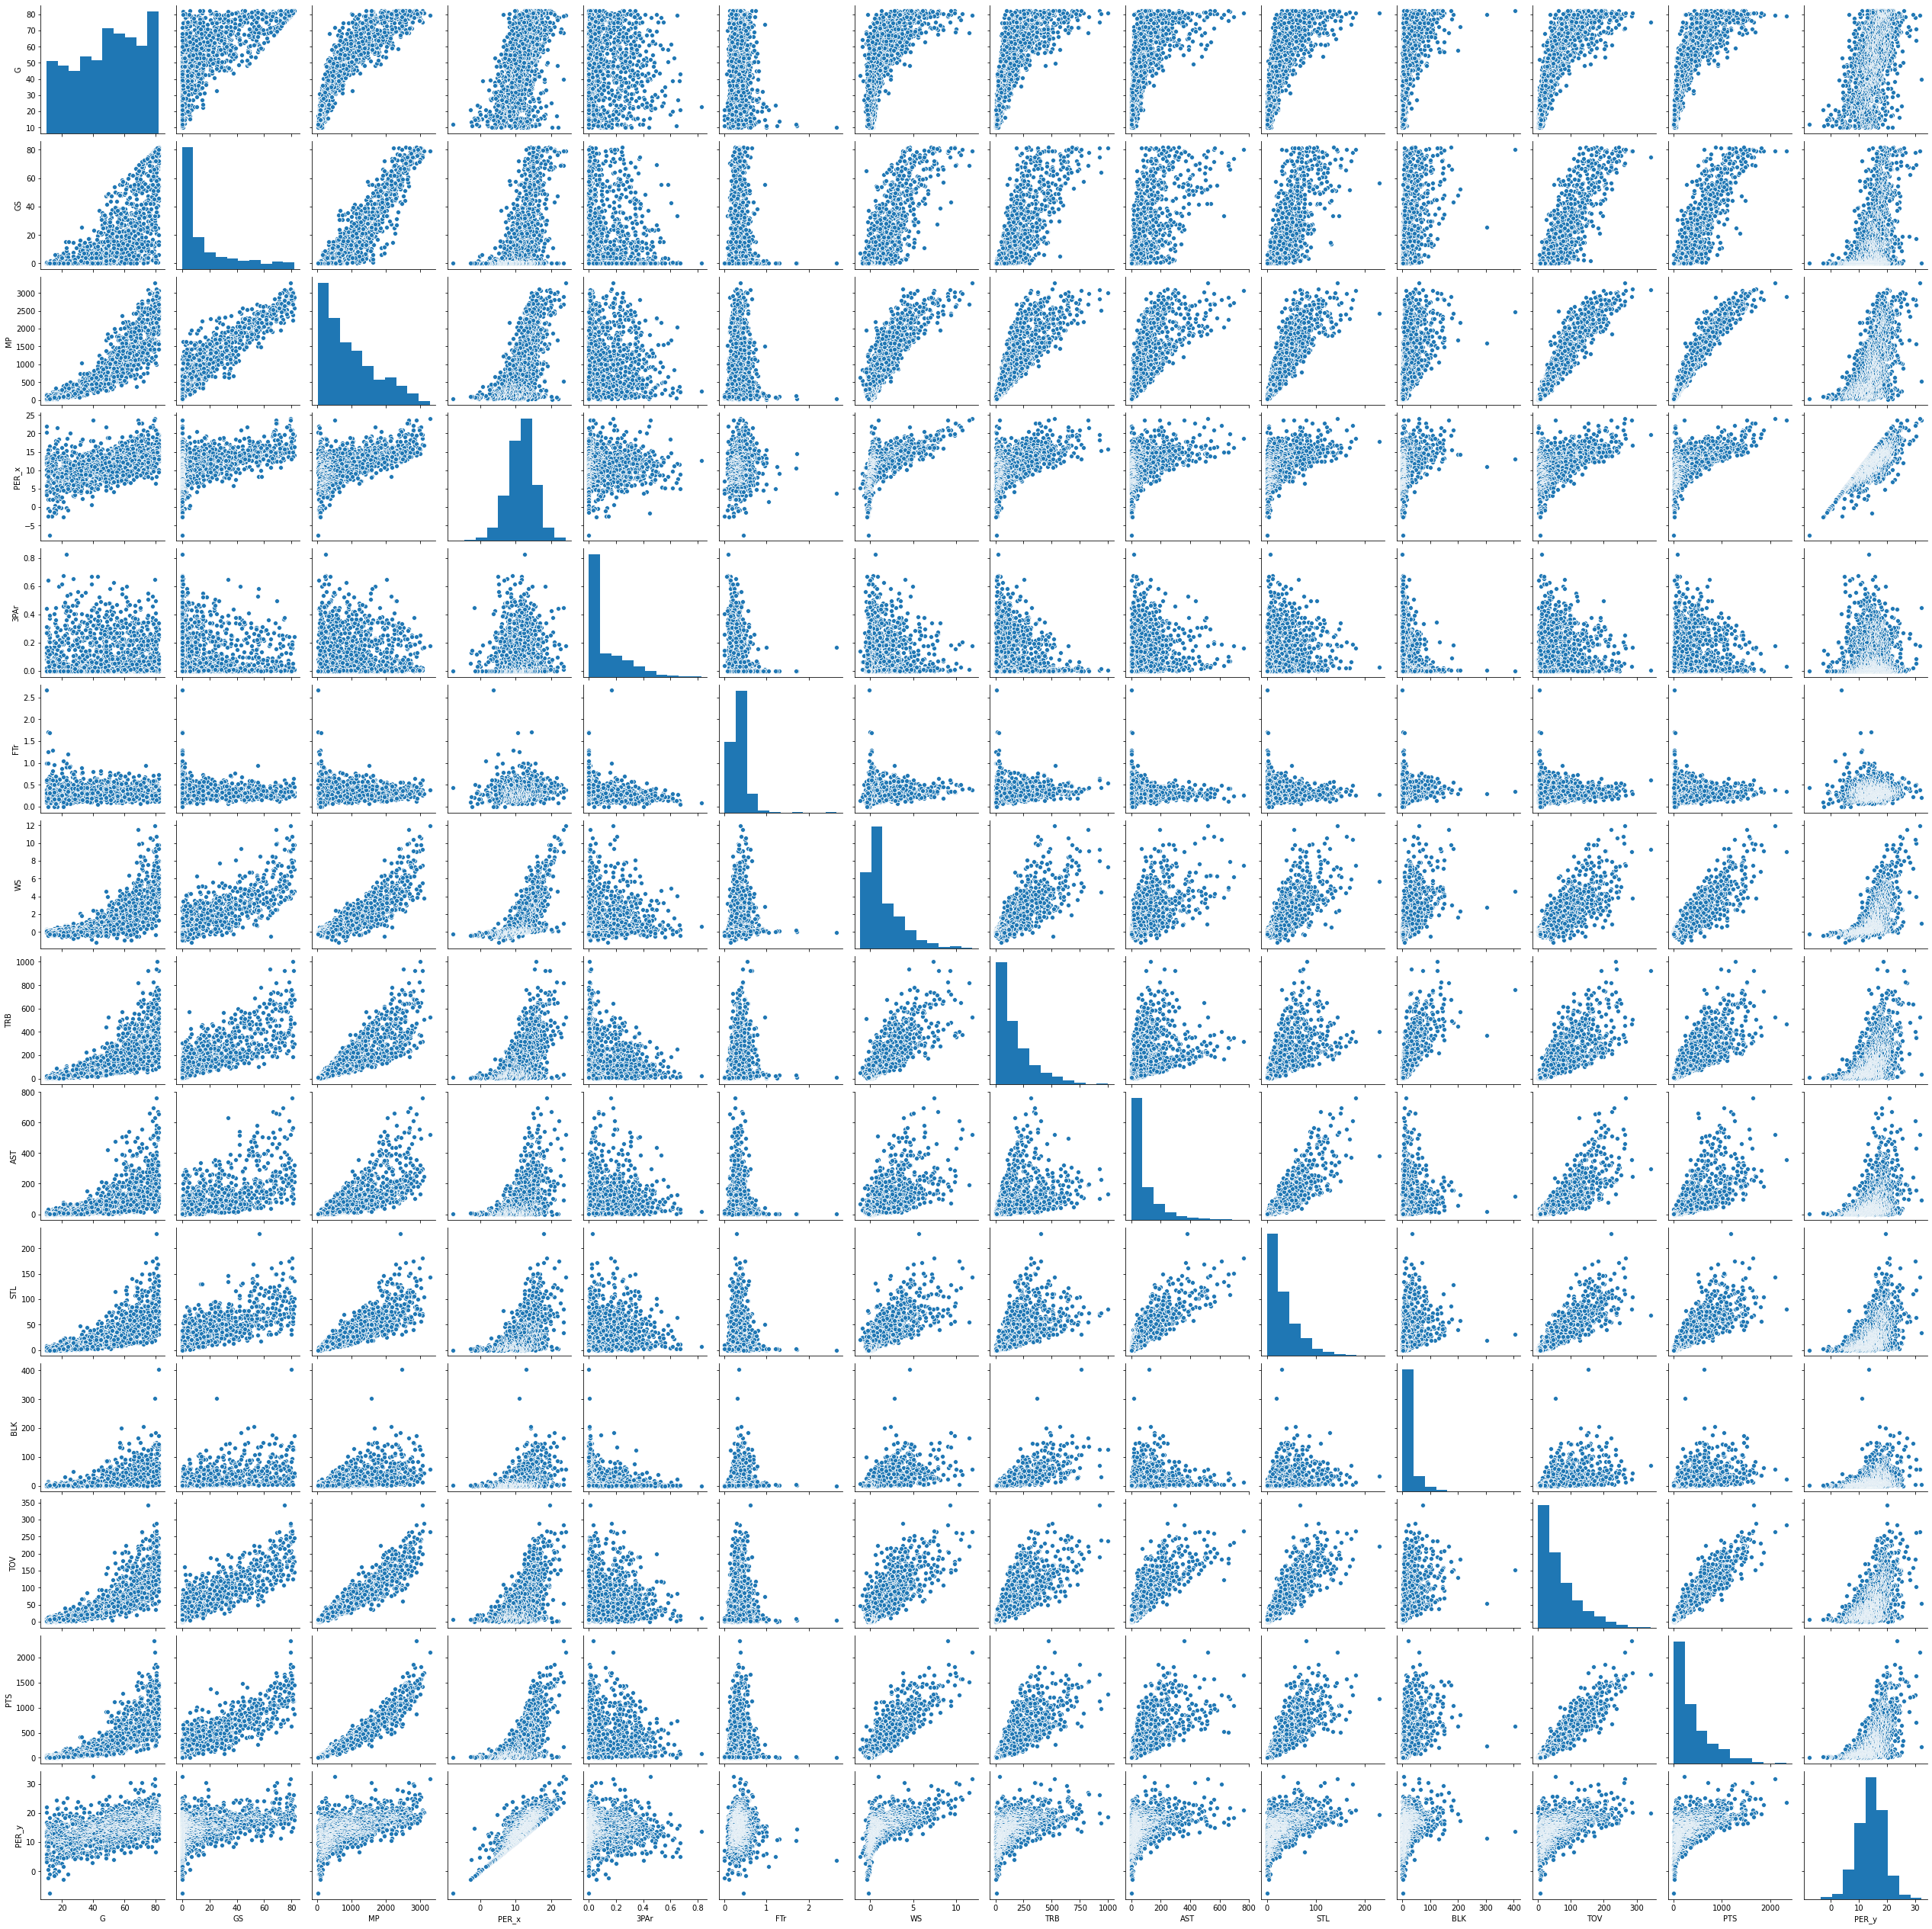

In [0]:
#Distribution
sns.pairplot(dfcharts)

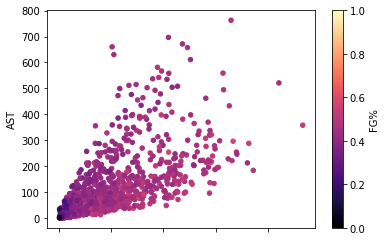

In [0]:
#Analysing 3 variables.
#Charts shows how assists and points impact Field Goals% 

ax2 = dftrain3.plot.scatter(x='PTS', y='AST',c='FG%', colormap='magma')

Well relationship between these 3 variables (assist, Points and Field Goals%, because a ball moves faster than defenders do, good passes are better able to find a player who is not closely defended at the time. So, it makes sense that a team who records more assists are providing more good opportunities.


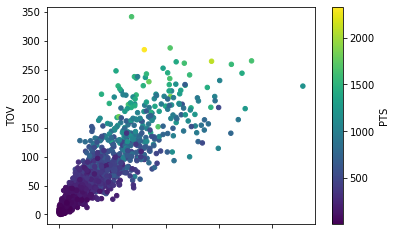

In [0]:
#Charts shows how steals and Turnover impact the points
ax2 = dfcharts.plot.scatter(x='STL', y='TOV',c='PTS', colormap='viridis')

well-correlated plot between turnovers and steals. 
The turnover in basketball gives crucial possessions to the opponent which in turn relates to points lost for the team.

# Build a linear regression model: Baseline Model

Here we build a baseline linear regression model. Our goal is to then improve upon it.

In [0]:
#Define X and Y 
X=dftrain3.loc[:, dftrain3.columns!= 'PER_y'] 
y=dftrain3['PER_y']

In [0]:
#Normalize the variables so they are all on the same scale
X = preprocessing.normalize(X) 

In [0]:
#Split into training and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
X_train.shape

(1129, 25)

In [0]:
#Build a linear regression model by puttig 80% of the dftrain dataset
regressor = LinearRegression()  
regressor.fit(X_train, y_train)


LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

In [0]:
#Make predictions using our model
y_pred = regressor.predict(X_test) 


In [0]:
#Evaluate performance on the test set
df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
df.head(25)

,Actual,Predicted
Player,,
Darrick Martin,17.0,16.100693
James Robinson,12.7,14.618844
Rusty LaRue,10.0,11.055540
Jason Williams,17.1,15.464068
Steve Blake,14.5,13.655621
Lamond Murray,17.8,14.162021
Evan Eschmeyer,11.8,13.490473
George McCloud,17.0,12.140985
Caron Butler,20.7,16.328060


Above we can see the model run on 25 players. It is clear that the model has potential, as many of the predictions were within +/- 2 of actual PER. In the case of Mike Dunleavy, Terry Dehere and Kenny Green, the model was practically spot on!



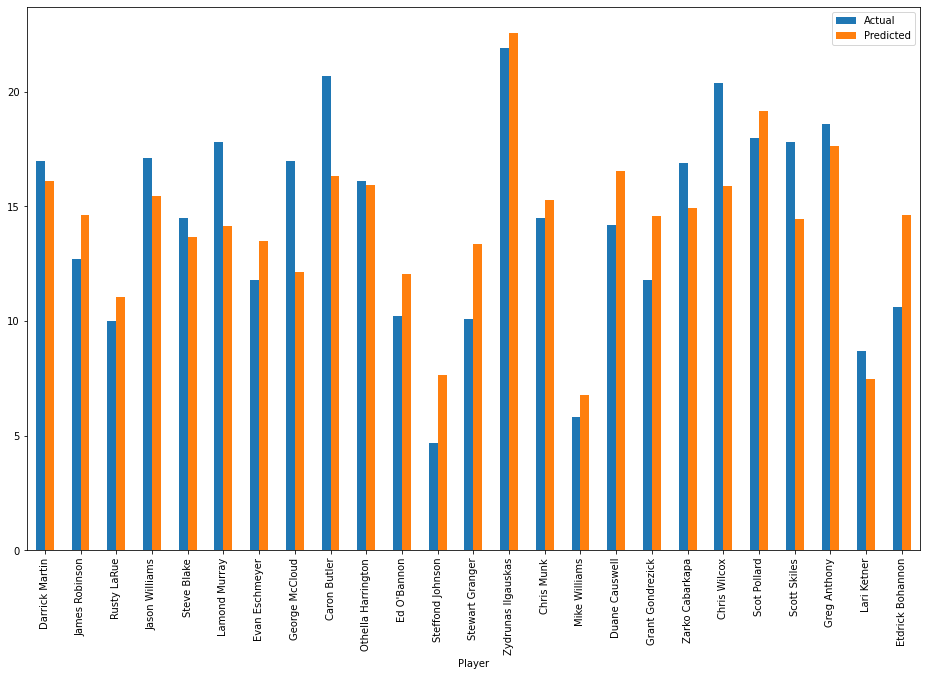

In [0]:
#Visualize our predictions
df1 = df.head(25)
df1.plot(kind='bar',figsize=(16,10))
plt.show()

In [0]:
#Run model evaluation metrics
print('Mean Absolute Error:', metrics.mean_absolute_error(y_test, y_pred))  
print('Mean Squared Error:', metrics.mean_squared_error(y_test, y_pred))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

Mean Absolute Error: 2.070219518390587
Mean Squared Error: 8.054455259636764
Root Mean Squared Error: 2.838037219565093


The model is pretty effective for a baseline. We are able to predict within +/- 2 of actual MAX PER, and the R-squared value is strong. 

/usr/local/lib/python3.6/dist-packages/seaborn/axisgrid.py:1848: UserWarning: JointGrid annotation is deprecated and will be removed in a future release.
  warnings.warn(UserWarning(msg))


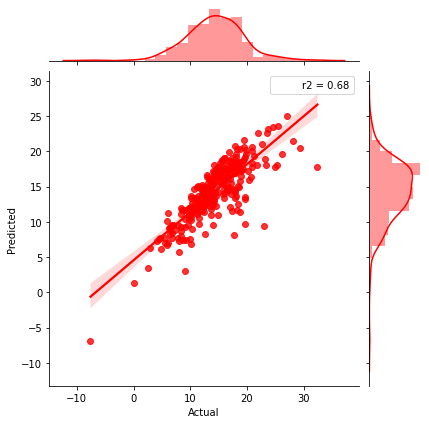

In [0]:
sns.jointplot(x="Actual", y="Predicted", data=df, kind="reg", color="r", stat_func=r2);


The model for the chart on the top is very accurate, there’s a strong correlation between the model’s predictions and its actual results

# Test the model on a seperate training set


Now, we will test the model on a completely seperate test set, showing players for the years 2007 to 2012

We will repeat many of the same steps from before

In [0]:

dftest=dffinal[(dffinal.Year>=2007) & (dffinal.Year<=2012)]
dftest=dftest[dftest.Season<=3]
dftest2=dftest.merge(MAXPER, left_on='Player', right_on='Player') #Merge maxper onto the training set. MAXPER is our Y
dftest3=dftest2.groupby(by="Player").mean() #Take the average of the three years the player spent in the league
dftest3=dftest3.dropna(axis=0)
droplist3=["Year", "Season", "year_start", "Age"] 
dftest3=dftest3.drop(columns=droplist3) #Drop columns we wont need inside our model
y=dftest3['PER_y']
X2=dftest3.loc[:, dftest3.columns!= 'PER_y']
X2 = preprocessing.normalize(X2)


In [0]:
y.shape

(465,)

In [0]:
y_pred2 = regressor.predict(X2) 
y_pred2.shape

(465,)

In [0]:
#Evaluate performance on the seperate test set
df4 = pd.DataFrame({'Actual': y, 'Predicted': y_pred2})
df4.head(20)

,Actual,Predicted
Player,,
A.J. Price,17.1,15.351713
Aaron Brooks,16.0,18.031873
Aaron Gray,18.4,16.500249
Acie Law,16.0,12.726620
Adam Morrison,7.9,10.598989
Al Horford,22.0,19.605199
Al Jefferson,23.1,21.131078
Al Thornton,12.7,14.669813
Al-Farouq Aminu,14.4,12.521514


In [0]:
print('Mean Absolute Error:', metrics.mean_absolute_error(y, y_pred2))  
print('Mean Squared Error:', metrics.mean_squared_error(y, y_pred2))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y, y_pred2)))

Mean Absolute Error: 2.3556405784408705
Mean Squared Error: 9.975821368618988
Root Mean Squared Error: 3.15845236921803


While not as effective as before, our baseline still performs fairly well on the new set

/usr/local/lib/python3.6/dist-packages/seaborn/axisgrid.py:1848: UserWarning: JointGrid annotation is deprecated and will be removed in a future release.
  warnings.warn(UserWarning(msg))


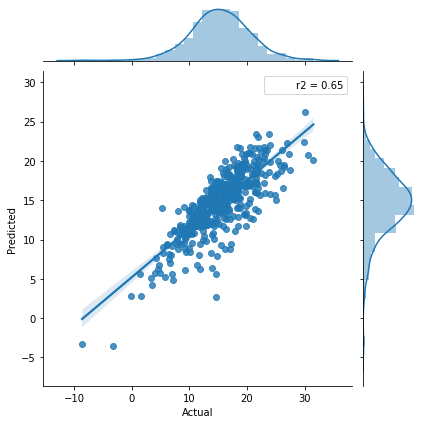

In [0]:
sns.jointplot(x="Actual", y="Predicted", data=df4, kind="reg", stat_func=r2);

# Improved Models

Moving forward, efforts will be made to improve the baseline model

## Now use the same training set and use it on the players who played from 1984 to 2006 and were in their senior years. This is to check how closely our model predicts their maximum PER in senior years

In [0]:
'''Now let's test the same training set on the players who have played more than three seasons'''


dftest=dffinal[(dffinal.Year>=1984) & (dffinal.Year<=2006)]
dftest=dftest[dftest.Season>3] # This time applying the model on the players in their senior years
dftest2=dftest.merge(MAXPER, left_on='Player', right_on='Player') #Merge maxper onto the training set. MAXPER is our Y
dftest3=dftest2.groupby(by="Player").mean() #Take the average of the three years the player spent in the league
dftest3=dftest3.dropna(axis=0)
droplist3=["Year", "Season", "year_start", "Age"] 
dftest3=dftest3.drop(columns=droplist3) #Drop columns we wont need inside our model
y=dftest3['PER_y']
X3=dftest3.loc[:, dftest3.columns!= 'PER_y']
X3 = preprocessing.normalize(X3)
y.shape



(946,)

In [0]:
X3.shape

(946, 25)

In [0]:
y_pred3 = regressor.predict(X3)
y_pred3[0:10]

array([17.13222063, 15.38318671, 16.81479964, 12.56419993, 15.01212445,
       14.66292906, 20.70080247,  9.95747796, 13.80134585, 17.2151195 ])

In [0]:
#Evaluate performance on the seperate test set
df5 = pd.DataFrame({'Actual': y, 'Predicted': y_pred3})
df5.head(10)

,Actual,Predicted
Player,,
A.C. Green,17.8,17.132221
Aaron McKie,15.8,15.383187
Aaron Williams,17.7,16.814800
Acie Earl,14.1,12.564200
Adam Keefe,15.1,15.012124
Adonal Foyle,19.7,14.662929
Adrian Branch,18.8,20.700802
Adrian Caldwell,10.4,9.957478
Adrian Griffin,14.2,13.801346


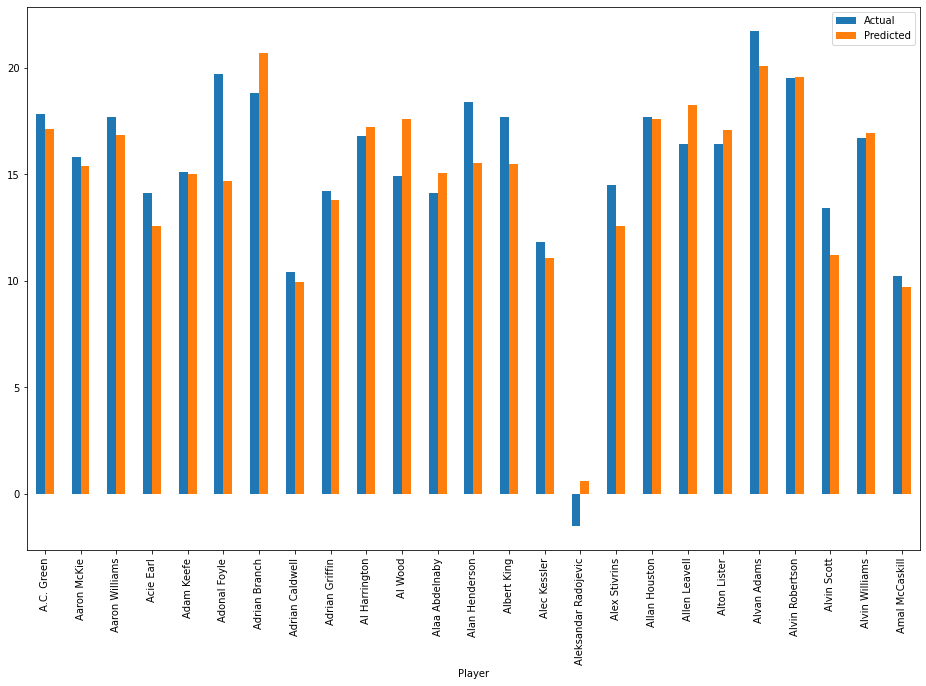

In [0]:
df5.head(25).plot(kind='bar',figsize=(16,10))
plt.show()

In [0]:
print('Mean Absolute Error:', metrics.mean_absolute_error(y, y_pred3))  
print('Mean Squared Error:', metrics.mean_squared_error(y, y_pred3))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y, y_pred3)))

Mean Absolute Error: 1.6655166241954695
Mean Squared Error: 6.086864036781702
Root Mean Squared Error: 2.4671570758226364


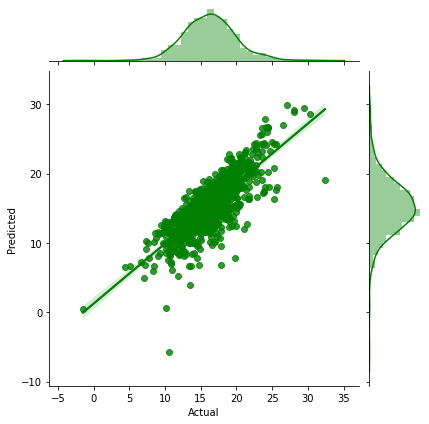

In [0]:
sns.jointplot(x="Actual", y="Predicted", data=df5, kind="reg", color="g", stat_func=r2);

We see that this model predicted pretty closely of how the players PER will be in their senior years. The mean variance is about 1.5 and R-squared value is good as well

# In order to try making the model more accurate this time instead of putting 80% of training set we will put the entire set in it. In order words we will use the entire dataset of players in their rookie years for the testing to check whether we are able to predict how will they do in their senior years

In [0]:
# Now instead of taking just 80% for training set lets take it full (season<3) and apply on players 1984 to 2006 (season>3)'''
X_train_Full = dftrain3.loc[:, dftrain3.columns!= 'PER_y'] 
X_train_Full.shape

(1412, 25)

In [0]:
y_train_Full = dftrain3['PER_y']

In [0]:
regressor8 = LinearRegression()  
regressor8.fit(X_train_Full, y_train_Full) # Training our model

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

In [0]:
y_pred8 = regressor8.predict(X3)

In [0]:
df6 = pd.DataFrame({'Actual': y, 'Predicted': y_pred8})
df6.head(10)

,Actual,Predicted
Player,,
A.C. Green,17.8,1.417177
Aaron McKie,15.8,1.419337
Aaron Williams,17.7,1.425090
Acie Earl,14.1,1.433569
Adam Keefe,15.1,1.421457
Adonal Foyle,19.7,1.419666
Adrian Branch,18.8,1.556039
Adrian Caldwell,10.4,1.432865
Adrian Griffin,14.2,1.422141


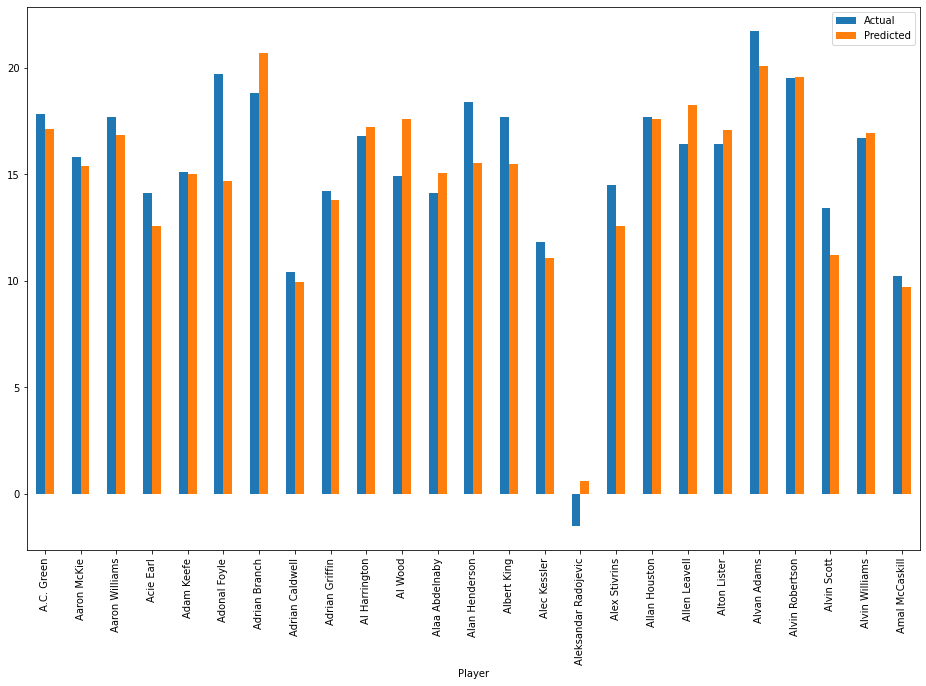

In [0]:
df6.head(25).plot(kind='bar',figsize=(16,10))
plt.show()

In [0]:
print('Mean Absolute Error:', metrics.mean_absolute_error(M_y, y_pred4))  
print('Mean Squared Error:', metrics.mean_squared_error(M_y, y_pred4))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(M_y, y_pred4)))

Mean Absolute Error: 1.6655166241954695
Mean Squared Error: 6.086864036781702
Root Mean Squared Error: 2.4671570758226364


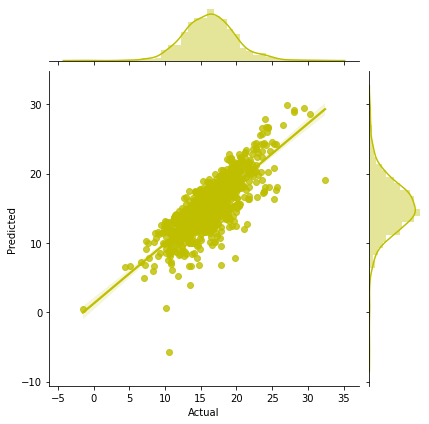

In [0]:
sns.jointplot(x="Actual", y="Predicted", data=df6, kind="reg", color="y", stat_func=r2);

# Model5


In [0]:
''' Now instead of taking just 80% for training set lets take it full (season<3) and apply on players 1984 and more (season>3)'''

dftest_Full=dffinal[(dffinal.Year>=1984)]
# dftest_Full_exp.size
# dftest_Full2.size
# third = dftest_Full2.groupby(by="Player").mean()
# third.shape

In [0]:
# a = dffinal[(dffinal.Year>=1984) & (dffinal.Year<=2006)]
# a = a[a.Season > 3]
# a2 = a.merge(MAXPER, left_on='Player', right_on='Player')
# a3 = a2.groupby(by="Player").mean()
# a3.dropna(axis= 0).shape

In [0]:
MAXPER_Full=dftest_Full.groupby(by="Player").max()['PER']
MAXPER_Full

Player
A.C. Green            17.8
A.J. English          12.5
A.J. Guyton           11.8
A.J. Hammons           8.4
A.J. Price            17.1
                      ... 
Zeljko Rebraca        16.2
Zendon Hamilton       18.2
Zoran Dragic           8.2
Zoran Planinic        12.5
Zydrunas Ilgauskas    21.9
Name: PER, Length: 2265, dtype: float64

In [0]:
#Apply the model to the seperate test set. We repeat many of the step from before on this new set

dftest_Full_exp=dftest_Full[dftest_Full.Season>3] # This time applying the model on the players in their senior years
dftest_Full2=dftest_Full_exp.merge(MAXPER_Full, left_on='Player', right_on='Player') #Merge maxper onto the training set. MAXPER is our Y
dftest_Full3=dftest_Full2.groupby(by="Player").mean() #Take the average of the three years the player spent in the league
#dftest_Full3=dftest_Full3.dropna(axis=0)
droplist4=["Year", "Season", "year_start", "Age"] 
dftest_Full3=dftest_Full3.drop(columns=droplist4) #Drop columns we wont need inside our model
y_full=dftest_Full3['PER_y']
X4=dftest_Full3.loc[:, dftest_Full3.columns!= 'PER_y']
#X2 = preprocessing.normalize(X)
y_full.shape

(1399,)

In [0]:
regressor5 = LinearRegression()  
regressor5.fit(X_train_F, y_train_F) # full training sets taken out in last example

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

In [0]:
y_pred5 = regressor.predict(X4)
y_pred5.shape

(1399,)

In [0]:
df7 = pd.DataFrame({'Actual': M_y, 'Predicted': y_pred3})
df7.head(10)

,Actual,Predicted
Player,,
A.C. Green,17.8,17.268240
Aaron McKie,15.8,15.174624
Aaron Williams,17.7,15.135287
Acie Earl,14.1,13.377811
Adam Keefe,15.1,14.587294
Adonal Foyle,19.7,15.401913
Adrian Branch,18.8,19.653350
Adrian Caldwell,10.4,10.089119
Adrian Griffin,14.2,11.779655


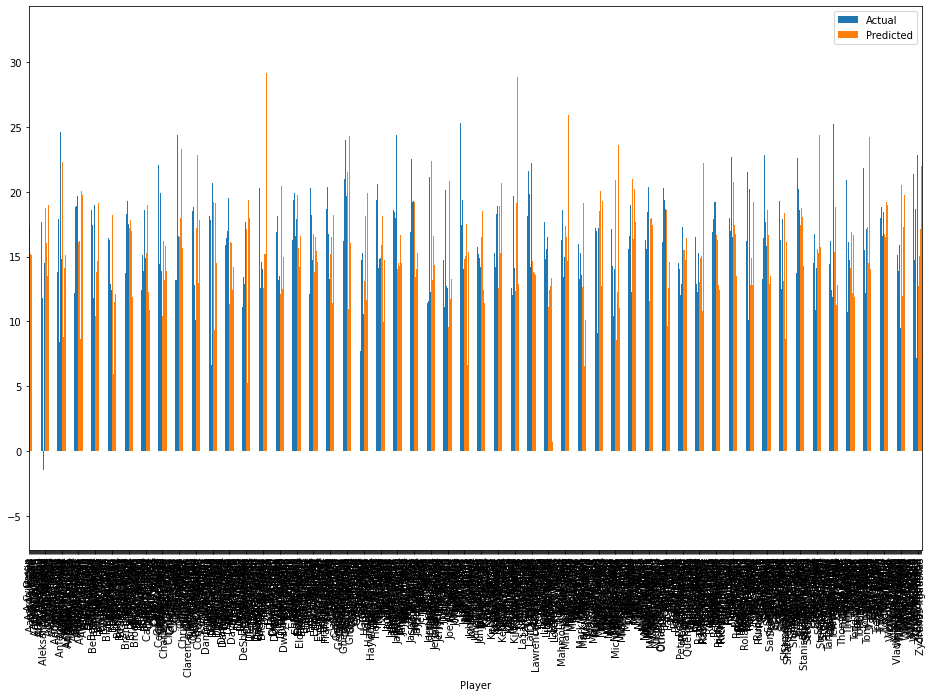

In [0]:
df7.plot(kind='bar',figsize=(16,10))
plt.show()

In [0]:
print('Mean Absolute Error:', metrics.mean_absolute_error(y_full, y_pred5))  
print('Mean Squared Error:', metrics.mean_squared_error(y_full, y_pred5))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_full, y_pred5)))

Mean Absolute Error: 1.7831873196683157
Mean Squared Error: 5.98150161675689
Root Mean Squared Error: 2.4457108612337826


# Conclusion

# Limitations and use cases

Although PER is a strong  measure of overall basketball talent, it is not perfect. There are two main areas in which it is deficient as a metric: 1) defensive talent and 2) qualitative 'intangibles'.

PER is worse at measuring defensive talent than offensive talent because defensive talent remains inherently more difficult to quantify. Defense can be thought of as the suppression (rather than creation) of scoring events, meaning that there are comparatively fewer basketball statistics that accurately meaure defensive ability. Good defense is often more subtle than good offense, and if a player fails to score on a given possession it is difficult to quantify the impact of how well they were defended. PER does its best by making use of many common defensive stats - blocks, rebounds, steals, etc. - but nonetheless remains an imperfect measure of defensive talent because it is hard to measures events not occurring.

PER is also limited in that it is blind to all qualitative and intangible factors. Basketball is played on the court, not on a spreadsheet, and so there are many things that impact individual and team-level success that do not show up in a player's statistics. For example, PER does not tell us whether a player is a good leader, whether they are dedicated to their craft and committed to improving, how open they are to feedback from coaches, how they interact with teammates, or what impact they have on team morale. These are all important considerations for NBA managers as they assemble their teams, but PER is blind to these considerations and others like them. For these reasons, we believe that statistics such as PER should be used to supplement traditional qualitative assessments ("the eye test") rather than replace them altogether.
